# Notebook 02 | Statistical Analysis
**Global Superstore – Customer Segmentation & Behavioral Analytics**

**Goal:** test two questions with proper statistics instead of eyeballing charts.

1. Do the six RFM segments differ in **profit margin**? (Kruskal-Wallis + Dunn post-hoc + effect size)
2. Is a customer's **average discount** associated with their **profit margin**? (Pearson and Spearman)

| | |
|---|---|
| **Input** | `customer_features.csv` (from notebook 01) and the SQL view `customer_rfm_segments` |
| **Why rank-based tests?** | Margins are skewed with outliers, so normality-based tests (ANOVA) are not appropriate |

## Setup

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import scikit_posthocs as sp   # Dunn post-hoc test

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [5]:
customer_df = pd.read_csv("customer_features.csv")
print("Dataset shape:", customer_df.shape)

customer_df.info()

Dataset shape: (4873, 20)
<class 'pandas.DataFrame'>
RangeIndex: 4873 entries, 0 to 4872
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              4873 non-null   str    
 1   total_orders             4873 non-null   int64  
 2   total_sales              4873 non-null   float64
 3   total_profit             4873 non-null   float64
 4   total_quantities         4873 non-null   int64  
 5   avg_items_per_order      4873 non-null   float64
 6   avg_order_value          4873 non-null   float64
 7   avg_profit_per_order     4873 non-null   float64
 8   first_purchase_date      4873 non-null   str    
 9   last_purchase_date       4873 non-null   str    
 10  active_months            4873 non-null   int64  
 11  avg_discount             4873 non-null   float64
 12  profit_margin            4873 non-null   float64
 13  unique_products          4873 non-null   int64  
 14  unique_ca

## Load the RFM segments from PostgreSQL
Segments are defined in SQL (`sql/03_customer_segmentation.sql`) and joined here by `customer_id`.

In [10]:
import os
from sqlalchemy import create_engine, URL

# Credentials are read from environment variables - never hard-code passwords in a repo.
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PGUSER", "postgres"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST", "127.0.0.1"),
    port=int(os.getenv("PGPORT", 5432)),
    database=os.getenv("PGDATABASE", "superstore_project"),
)
engine = create_engine(db_url)
print("Database engine created successfully!")

Database engine created successfully!


In [13]:
rfm_df = pd.read_sql(
    "SELECT * FROM customer_rfm_segments",
    engine
)

print(rfm_df.shape)
print(rfm_df.columns.tolist())
rfm_df.head()

(4873, 7)
['customer_id', 'r_score', 'f_score', 'm_score', 'rfm_score', 'segment', 'segment_rule']


,customer_id,r_score,f_score,m_score,rfm_score,segment,segment_rule
0,DP-133902,5,4,3,12,LOYAL CUSTOMER,"F >= 4, R >= 3, M >= 3; excluding Champions"
1,LP-70951,5,1,1,7,NEEDS ATTENTION,RFM score between 7 and 9; excluding earlier s...
2,SC-202603,5,4,2,11,POTENTIAL LOYALIST,"R >= 4, F >= 2, M >= 2; excluding earlier segm..."
3,RD-194802,5,4,5,14,CHAMPIONS,"R >= 4, F >= 4, M >= 4"
4,KM-162251,5,5,5,15,CHAMPIONS,"R >= 4, F >= 4, M >= 4"


In [ ]:
# Attach each customer's SQL-defined RFM segment (one row per customer_id)
overlap = [c for c in rfm_df.columns if c != "customer_id" and c in customer_df.columns]
customer_df = customer_df.drop(columns=overlap).merge(rfm_df, on="customer_id", how="left")

assert customer_df["segment"].notna().all(), "Some customers have no segment"
print("Customers with a segment:", customer_df["segment"].notna().sum())

In [23]:
customer_df[
    ["customer_id", "r_score", "f_score", "m_score",
     "rfm_score", "segment", "segment_rule"]
].head()

,customer_id,r_score,f_score,m_score,rfm_score,segment,segment_rule
0,SM-203204,3,3,5,11,LOW ENGAGEMENT CUSTOMER,Does not meet any previous segment rule
1,TC-209804,1,3,5,9,AT-RISK VALUABLE CUSTOMER,"R <= 2, F >= 3, M >= 3"
2,CS-118451,5,5,5,15,CHAMPIONS,"R >= 4, F >= 4, M >= 4"
3,SP-209202,2,5,5,12,AT-RISK VALUABLE CUSTOMER,"R <= 2, F >= 3, M >= 3"
4,VG-218051,3,4,5,12,LOYAL CUSTOMER,"F >= 4, R >= 3, M >= 3; excluding Champions"


In [24]:
customer_df["segment"].value_counts()

segment
LOW ENGAGEMENT CUSTOMER      1485
CHAMPIONS                     796
NEEDS ATTENTION               694
POTENTIAL LOYALIST            685
LOYAL CUSTOMER                616
AT-RISK VALUABLE CUSTOMER     597
Name: count, dtype: int64

## Part 1 – Do RFM segments differ in profit margin?
Group summary and boxplot first, to choose a suitable test.

In [25]:
customer_df.groupby("segment")["profit_margin"].agg(
    ["count", "mean", "median", "std"]
).round(3)

,count,mean,median,std
segment,,,,
AT-RISK VALUABLE CUSTOMER,597,10.929,14.210,17.022
CHAMPIONS,796,11.407,13.705,14.880
LOW ENGAGEMENT CUSTOMER,1485,0.635,14.770,44.573
LOYAL CUSTOMER,616,9.772,12.895,15.715
NEEDS ATTENTION,694,6.043,13.075,30.213
POTENTIAL LOYALIST,685,11.221,15.540,21.920


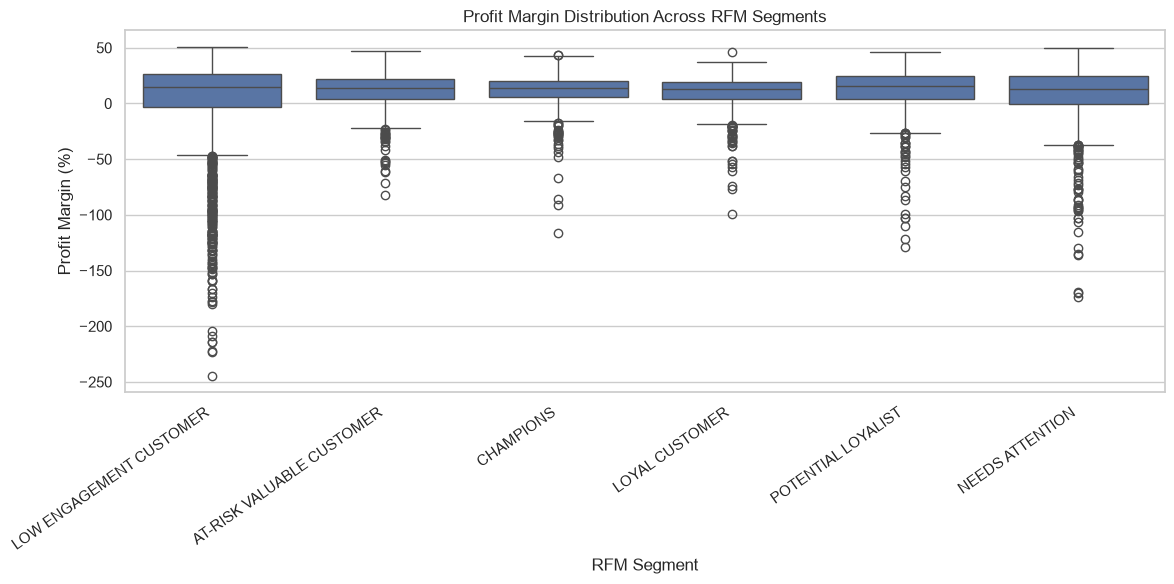

In [ ]:
#vizualize the distribution for choosing a valid statistical test

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=customer_df,
    x="segment",
    y="profit_margin"
)

plt.xticks(rotation=35, ha="right")
plt.title("Profit Margin Distribution Across RFM Segments")
plt.xlabel("RFM Segment")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

**Hypotheses**
- H₀: all six segments have the same profit-margin distribution.
- H₁: at least one segment differs.

The **Kruskal-Wallis** test is used because margin is not normally distributed and group sizes differ.

In [28]:
#kruksal test

groups=[
    group["profit_margin"].dropna()
    for _, group in customer_df.groupby('segment')
]

kruskal_result = stats.kruskal(*groups)

print("Kruskal-Wallis H-statistic:", kruskal_result.statistic)
print("P-value:", kruskal_result.pvalue)

Kruskal-Wallis H-statistic: 17.63798786242919
P-value: 0.0034360594771083103


**Result:** H = 17.64, p = 0.0034 → p < 0.05, so we reject H₀: at least one segment's margin distribution differs.

A significant result does not say *which* segments differ or *how much*, so we follow up with a post-hoc test and an effect size.

In [37]:
# Post-hoc: which pairs of segments differ? (Dunn test, Bonferroni-adjusted p-values)
posthoc = sp.posthoc_dunn(
    customer_df,
    val_col="profit_margin",
    group_col="segment",
    p_adjust="bonferroni"
)

posthoc

,AT-RISK VALUABLE CUSTOMER,CHAMPIONS,LOW ENGAGEMENT CUSTOMER,LOYAL CUSTOMER,NEEDS ATTENTION,POTENTIAL LOYALIST
AT-RISK VALUABLE CUSTOMER,1.000000,1.000000,1.000,0.795465,1.000000,0.928292
CHAMPIONS,1.000000,1.000000,1.000,1.000000,1.000000,0.172888
LOW ENGAGEMENT CUSTOMER,1.000000,1.000000,1.000,0.056000,1.000000,1.000000
LOYAL CUSTOMER,0.795465,1.000000,0.056,1.000000,1.000000,0.001543
NEEDS ATTENTION,1.000000,1.000000,1.000,1.000000,1.000000,0.150479
POTENTIAL LOYALIST,0.928292,0.172888,1.000,0.001543,0.150479,1.000000


In [36]:
# Smallest adjusted p-value = the most significant pair; the maximum (1.0) is the diagonal (a segment vs itself)
print(posthoc.min().min())
print(posthoc.max().max())

0.001542978855238429
1.0


**Effect size (epsilon-squared)** – how much of the variation in margin is explained by segment membership.

In [38]:
H = kruskal_result.statistic
k = customer_df["segment"].nunique()
n = customer_df["profit_margin"].count()

epsilon_squared = (H - k + 1) / (n - k)

print("Epsilon squared:", epsilon_squared)

Epsilon squared: 0.002596668967008257


**Interpretation:** epsilon² ≈ 0.0026, i.e. segment membership explains well under 1% of the variation in margin. The difference is statistically significant (large sample) but **practically negligible**. RFM tells us how *engaged* a customer is, not how *profitable*; profitability has to be analysed separately (discounts, products, markets).

## Part 2 – Discount intensity vs customer profit margin
Do customers who receive higher average discounts earn lower margins?

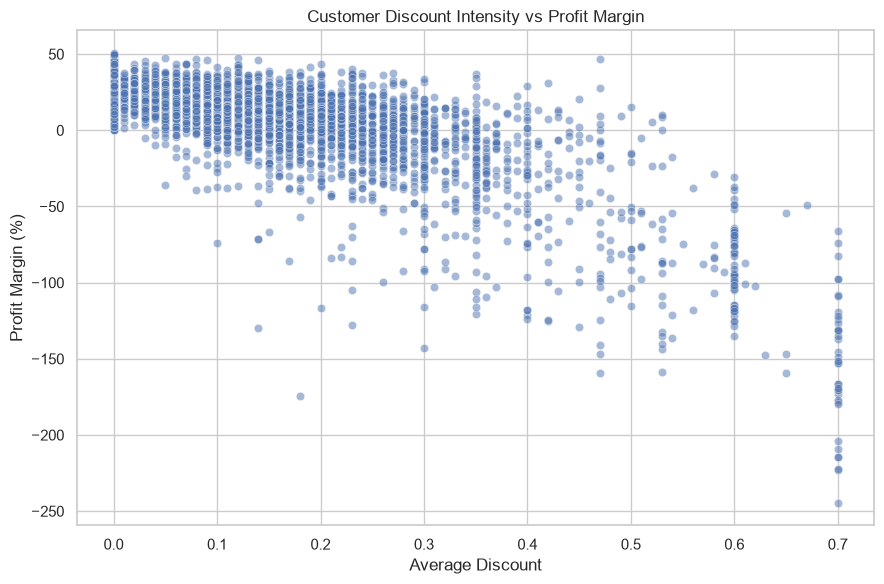

In [39]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_df,
    x="avg_discount",
    y="profit_margin",
    alpha=0.5
)

plt.title("Customer Discount Intensity vs Profit Margin")
plt.xlabel("Average Discount")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

Pearson (linear) and Spearman (rank-based) correlation with p-values.

In [44]:
pearson_corr, pearson_p = stats.pearsonr(
    customer_df["avg_discount"],
    customer_df["profit_margin"]
)

spearman_corr, spearman_p = stats.spearmanr(
    customer_df["avg_discount"],
    customer_df["profit_margin"]
)

print("Pearson correlation:", pearson_corr)
print("Pearson p-value:", pearson_p)

print("Spearman correlation:", spearman_corr)
print("Spearman p-value:", spearman_p)

Pearson correlation: -0.758069838722291
Pearson p-value: 0.0
Spearman correlation: -0.6548331720494083
Spearman p-value: 0.0


**Result:** Pearson ≈ -0.76 and Spearman ≈ -0.65 (both p < 0.001): higher average discount goes with lower profit margin.

**Caution:** this is an *association*. Discounts may have been given on products that already had thin margins, so these results do not prove that discounts *cause* the lower margin.